# PTM3D tutorial 02 — Europa, with a Jupiter eclipse

One Europa day over the whole moon. Europa is tidally locked, so its orbital
period around Jupiter *is* its diurnal period: 3.55 Earth days. Once per orbit
it passes through Jupiter's shadow and the direct solar flux drops to exactly
zero, body-wide, for about 2.7 hours — this run's `start_time` is chosen so the
output window contains one.

The notebook follows the same shape as
[`01_moon_diurnal.ipynb`](01_moon_diurnal.ipynb), which introduces the run
reader, the output format and the color-scale convention used here without
re-deriving them. Beyond the eclipse it covers what a too-short spin-up does to
a temperature map, what Europa's observed albedo map does to it, and what
happens to a hand-set albedo when that map is loaded.

**Cost:** CPU-only, about two minutes of engine time across nine runs on
a 5,120-face icosphere, under 1 GB of RAM. Radiation exchange is off (a convex sphere has no
self-view), so no GPU and no view-factor matrix.

**Needs:** the `ptm` package, a built `ptm_thermal_sim`, and the Europa SPICE
kernels — which, unlike the Moon's, include the 1.1 GB Galilean-satellite
ephemeris `jup365.bsp`, because Europa's position *relative to Jupiter* is what
produces the eclipse.

In [1]:
from ptm import paths, run as engine

CONFIG = "examples/quickstart_europa_diurnal.yaml"
pre = paths.preflight([CONFIG, "data/kernels/europa.tm",
                       "data/kernels/lsk/naif0012.tls",
                       "data/kernels/spk/jup365.bsp"], engine="ptm_thermal_sim")
print(pre)
pre.raise_if_missing()

found    /Users/paha3326/Projects/ptm-tut-thermophys/build-cpu/bin/ptm_thermal_sim
found    examples/quickstart_europa_diurnal.yaml
found    data/kernels/europa.tm
found    data/kernels/lsk/naif0012.tls
found    data/kernels/spk/jup365.bsp

Repo root: /Users/paha3326/Projects/ptm-tut-thermophys
Engine:    /Users/paha3326/Projects/ptm-tut-thermophys/build-cpu/bin/ptm_thermal_sim


<Report 5/5 found>

## 1. Run it

10-15 s on a many-core workstation, a minute or two on a laptop.

In [2]:
europa = engine.run_engine(pre.root / CONFIG, echo=True).results()

Running: /Users/paha3326/Projects/ptm-tut-thermophys/build-cpu/bin/ptm_thermal_sim --config /Users/paha3326/Projects/ptm-tut-thermophys/examples/quickstart_europa_diurnal.yaml
(cwd=/Users/paha3326/Projects/ptm-tut-thermophys)

╔═══════════════════════════════════════════════════════════════╗
║    *      .    *     \   ||    //      * .   .      *         ║
║       .      *     \  \  ||   //    //       .             .  ║
║  *      .       \   \  \  ☀  //    //      .      *           ║
║     .         *  \   ...-'''''-...//    *         .           ║
║           _ ... .-'''''   PTM3D     ``''-.....,__      .      ║
║   __,.-''    Planetary Thermophysical Model 3D     `'-..., _  ║
║  ═══════════════════════════════════════════════════════════  ║
║      Coupled Thermal-Illumination for Planetary Bodies        ║
╚═══════════════════════════════════════════════════════════════╝
Successfully loaded configuration from: /Users/paha3326/Projects/ptm-tut-thermophys/examples/quickstart_europa_di

========== Thermal Equilibration Configuration ==========
Body: Europa
Synodic day (solar day): 3.55 Earth days
Equilibration cycles: 20.00 day/night cycles
Total equilibration period: 71.00 Earth days
Output window (for export): 3.55 Earth days
Requested integration (stats): 3.55 days with offset 0.00 days
Post-equilibration simulated span: 3.55 Earth days
Total simulation time: 74.55 Earth days
Time step calculation:
Requested output time steps: 192
Output window (days): 3.55
Output cadence:        54.084507 steps/Earth-day
Equilibration cadence: 54.084507 steps/Earth-day [legacy (matches output cadence)]
Total simulation days: 74.550000
Equilibration steps: 3840
Output steps:        192
Total time steps (including equilibration and integration coverage): 4032
Running illumination simulation for 74.550000 days (including 71.000000 days equilibration) starting at 2024-10-22T00:00:00
[IlluminationModel] mesh topology: CLOSED (watertight) (0 boundary edges / 7680 unique edges, 5120 core

[illumination] NOTE: primary-disk probe found no above-horizon sample on a face whose analytic horizon clip is still positive (a ~sin^3(alpha)/2 sliver at the bottom of the band). Keeping the analytic, unoccluded value there; the flux involved is ~0. Warned once.
Calculating illumination:  [>                                                 ] 0% | elapsed 0s


Calculating illumination:  [============>                                     ] 25% | elapsed 1s, ETA 4s


Calculating illumination:  [=========================>                        ] 50% | elapsed 2s, ETA 2s


Calculating illumination:  [=====================================>            ] 75% | elapsed 4s, ETA 1s


... (6 outputs left out)

Progress 109/192


Progress 163/192


Progress 192/192
Export complete: 192/192
Binary export completed successfully!
Data successfully written in binary format to: output/quickstart_europa_diurnal
[Statistics] Exporting statistics over integration window...
[exportStatisticsBinary] Computing and exporting statistics...
Face count: 5120
Time steps: 192
Computing illumination statistics...
Computing direct solar statistics...
Computing primary reflected statistics...
Computing primary IR statistics...
Computing temperature statistics...
[exportStatisticsBinary] Statistics export completed successfully!
[Statistics] Exported to output/quickstart_europa_diurnal/statistics
[albedo] PTM-107(a) effective surface albedo (flux-weighted over the DIRECT beam, the value the BC absorbed with): global A_eff = 0.56723 over 5116/5120 ever-lit faces; per-face -> output/quickstart_europa_diurnal/statistics/effective_albedo.bin (uint32 n + float32[5120], NaN where never lit).
Reduced over the INTEGRATION window, abs steps [3840,4032) -- the

Memory cleanup completed.
Cleaning up remaining memory...
Cleanup completed successfully

--- 354 output lines; 10.2 s wall; exit code 0 ---


## 2. The first look

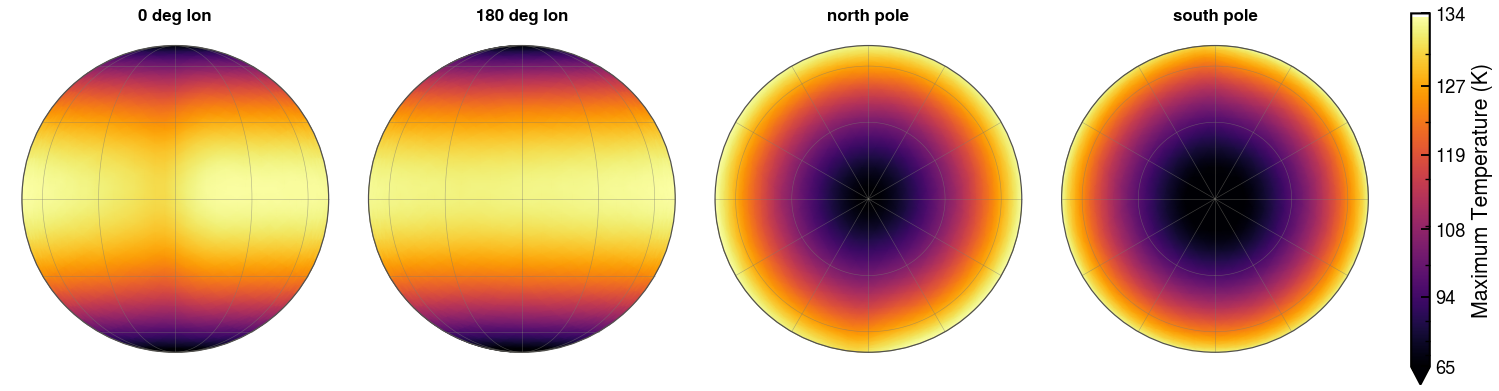

In [3]:
fig = europa.plot_globes("temperature", "max")

Clean latitude bands, as a smooth sphere of uniform ice must give. Peak
temperature reaches only about 135 K: Europa is 5.2 AU from the Sun, where the
solar constant is 3.7% of Earth's, and its ice is bright.

Two things will disturb those bands later. Section 7 shows a longitudinal ramp
that turns out to be a numerical artifact of the spin-up rather than anything
about Europa, and a narrow real notch at the sub-Jupiter meridian left by the
eclipse. Section 8 replaces the uniform albedo with the observed map.

## 3. The config

[`examples/quickstart_europa_diurnal.yaml`](../../../examples/quickstart_europa_diurnal.yaml)
is the Europa counterpart of tutorial 01's quickstart: small, fast, radiation
off. (`examples/europa_high_res.yaml` is the production-scale ico7 GPU config,
not a laptop quickstart.)

In [4]:
print((pre.root / CONFIG).read_text())

# PTM3D quickstart: Europa diurnal (one orbit) run on a small icosphere (ico4, 5120 faces).
#
# Laptop-friendly (CPU-only, radiation off, < 1 GB RAM, seconds of wall time). All
# paths are relative — run FROM THE REPOSITORY ROOT after fetching SPICE kernels:
#
#     python3 scripts/fetch_kernels.py --bodies europa   # once, ~1.1 GB from NAIF
#     ./build/bin/ptm_thermal_sim --config examples/quickstart_europa_diurnal.yaml
#
# Europa is tidally locked, so one "diurnal cycle" IS one orbit around Jupiter
# (3.55 Earth days) — unlike the Moon, whose 29.53-day synodic day is much
# longer than its (irrelevant, for surface heating) sidereal rotation.
#
# start_time is pinned to 2025-01-01T00:00:00 deliberately: at this epoch a
# full Jupiter eclipse (Europa passing through Jupiter's shadow) falls at
# ~18:06-20:33 UTC on day 1, i.e. inside this run's single-orbit output
# window. Direct solar flux drops to exactly zero, body-wide, for ~2.7 h
# (6 of 192 output steps) — Europa's signature ph

What is Europa-specific:

- **`body: Europa`** selects the built-in ephemeris, radius (1,560.8 km),
  ice-regolith defaults — Bond albedo 0.5, emissivity 0.9, thermal inertia
  $\Gamma \approx 60$ SI, internal heat flux $Q_b = 0.03$ W/m² — **and** Jupiter
  as the primary body, through `europa.tm`'s Galilean ephemeris. No config key
  names Jupiter.
- **Two Jupiter terms, gated differently.** Europa receives direct sunlight,
  sunlight reflected off Jupiter, and Jupiter's own thermal IR.
  `illumination.include_primary_reflection` controls *only* the reflected term.
  Jupiter's thermal IR runs unconditionally whenever the body has a non-Sun
  primary, so setting that key `false` removes Jupiter-shine and leaves
  Jupiter's IR heating in place. Exercise 3.
- **`equilibration_orbits: 20.0`** — twenty orbits of spin-up before the output
  window opens. Europa's icy regolith has a thin diurnal skin depth, about 5 cm,
  so the surface layer settles within an orbit or two; the layers below it take
  far longer. Section 7 is about exactly that.
- **`mesh.resolution: 4`** — 5,120 faces, one level finer than the Moon
  quickstart, compensating for Europa's smaller radius.

The output directory has the same layout as tutorial 01's, with one addition:
`body_positions.csv` carries **two** vectors per row, `sun_*` and `primary_*`,
both in km from Europa's center.

In [5]:
import numpy as np

for moment in ("max", "avg", "min"):
    v = europa.stat("temperature", moment)
    print(f"temperature_{moment:3s}   min {v.min():6.2f}   median {np.median(v):6.2f}"
          f"   max {v.max():6.2f} K")

tmax, tmin = europa.stat("temperature", "max"), europa.stat("temperature", "min")
cold = int(np.sum(tmax < 40.0))
print(f"\n{cold} of {tmax.size} faces never exceed 40 K even at their warmest: "
      "near-polar faces that this coarse mesh never lights.")

temperature_max   min  29.78   median 125.58   max 133.75 K
temperature_avg   min  29.76   median 102.74   max 108.39 K
temperature_min   min  29.74   median  89.40   max  93.44 K

8 of 5120 faces never exceed 40 K even at their warmest: near-polar faces that this coarse mesh never lights.


Those never-lit faces are a built-in check on the model's floor. A face that
receives no flux at any time must sit at the internal-heat-flux equilibrium
$T = (Q_b/\varepsilon\sigma)^{1/4}$, which for $Q_b = 0.03$ W/m² and
$\varepsilon = 0.9$ is 27.7 K. The coldest faces sit at 29.8 K — the remaining
2 K is grazing sunlight that this coarse mesh still delivers to them.

## 4. Finding the eclipse

An eclipse is a **global** event — the entire day side loses the Sun at once,
not a terminator sweeping across — so the clearest signature is the direct solar
flux summed over every face. `stack()` reads all output steps of a per-step
field into one `(n_steps, n_faces)` array.

In [6]:
direct = europa.stack("direct_solar")
eclipse = np.where(direct.sum(axis=1) < 1e-6)[0]
if eclipse.size == 0:
    raise RuntimeError("no eclipse in this output window; the eclipse analysis "
                       "below depends on the config's start_time capturing one")

utc = europa.times().utc
cadence_h = float(np.median(np.diff(europa.elapsed_hours)))
print(f"{eclipse.size} fully dark output steps at a {60 * cadence_h:.0f} min cadence "
      f"= at least {eclipse.size * cadence_h:.1f} h of total shadow")
print(f"{utc[eclipse[0]]} -> {utc[eclipse[-1]]}  (the steps on either side are already "
      "partway into ingress and egress, so the true eclipse is a little longer still)")

6 fully dark output steps at a 27 min cadence = at least 2.7 h of total shadow
2025-01-01T18:10:37.657 -> 2025-01-01T20:23:47.138  (the steps on either side are already partway into ingress and egress, so the true eclipse is a little longer still)


### The thermal fingerprint on one face

Take the face with the highest direct solar flux in the step immediately before
ingress — a face near local noon at that moment, so the most dramatic case — and
plot its whole diurnal curve with the eclipse window shaded.

cooled 23.7 K inside the shadow


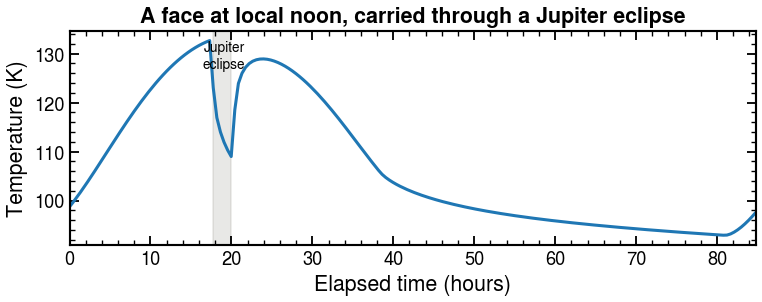

In [7]:
from ptm import plots

plt = plots.styled()                 # the project's figure style
face = int(np.argmax(direct[eclipse[0] - 1]))
t_hr, curve = europa.series("temperature", face=face)
cooling = curve[:eclipse[0]].max() - curve[eclipse[0]:eclipse[-1] + 1].min()

ax = europa.plot_diurnal(face=face).axes[0]
ax.set_title("A face at local noon, carried through a Jupiter eclipse")
ax.axvspan(t_hr[eclipse[0]], t_hr[eclipse[-1]], color="#8d8c82", alpha=0.2, zorder=0)
ax.text(t_hr[eclipse[len(eclipse) // 2]], curve.max(), "Jupiter\neclipse",
        ha="center", va="top", fontsize=9)
print(f"cooled {cooling:.1f} K inside the shadow")

The temperature does not follow the flux to zero. It falls about 24 K in those
2.7 hours and then, when sunlight returns, only partly recovers: the
post-eclipse peak lands below the pre-eclipse one, because the shadow cut off
part of the climb toward local noon.

Both features come from the same thin skin. Europa's porous-ice regolith
($k_s = 0.0096$ W/m/K, $\rho_s = 500$ kg/m³, $c_p \approx 750$ J/kg/K) has a
diurnal skin depth $\delta = \sqrt{\kappa P/\pi} \approx 5$ cm for a 3.55-day
period. A thin skin responds fast — hence a visible dip in under three hours —
but it also stores little heat. The flux discontinuity here, full daytime
insolation to zero in a single SPICE geometry transition, is why
`docs/thermal-model.md` describes an event-aware adaptive timestep controller.

## 5. Day/night contrast, and the comparison with the Moon

Moon (tutorial 01)   median face:  369.7 -  92.6 K, swing  277.1 K, Tmin/Tmax 0.25
Europa (this run)    median face:  125.6 -  89.4 K, swing   36.2 K, Tmin/Tmax 0.71


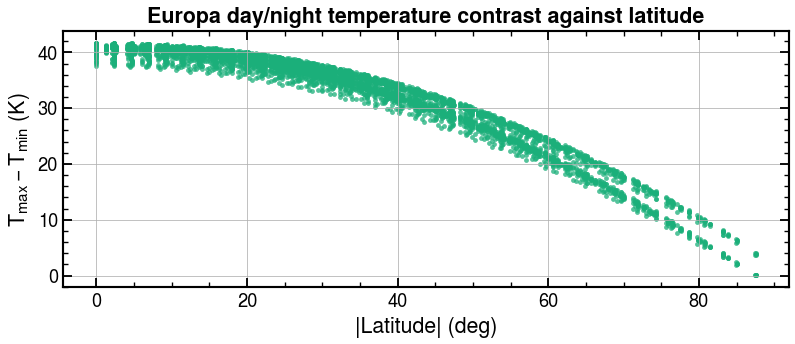

In [8]:
contrast = tmax - tmin
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.scatter(np.abs(europa.lat), contrast, s=10, alpha=0.75, linewidths=0, color="#1baf7a")
ax.set_xlabel("|Latitude| (deg)")
ax.set_ylabel(r"$T_\mathrm{max} - T_\mathrm{min}$ (K)")
ax.set_title("Europa day/night temperature contrast against latitude")
ax.grid(True, linewidth=0.5)
fig.tight_layout()

MOON_TMAX, MOON_TMIN = 369.7, 92.6            # medians from tutorial 01
for name, hi, lo in (("Moon (tutorial 01)", MOON_TMAX, MOON_TMIN),
                     ("Europa (this run)", float(np.median(tmax)), float(np.median(tmin)))):
    print(f"{name:20s} median face: {hi:6.1f} - {lo:5.1f} K, "
          f"swing {hi - lo:6.1f} K, Tmin/Tmax {lo / hi:.2f}")

The Moon's median face falls to a quarter of its peak temperature between noon
and dawn; Europa's only falls to seven tenths. The material is not the reason —
the two thermal inertias are broadly comparable. The night length is:
**Europa's night is 1.775 Earth days**, against the Moon's 14.75, so there is
roughly eight times less time for stored daytime heat to radiate away before
sunrise. The mechanism is the Moon's nighttime plateau; it is proportionally far
larger here because of the orbital period, not the regolith.

## 6. The eclipse as a global event

The same instant seen from the Sun's direction and from the night side, plus the
mid-eclipse step from the same viewpoint. One row of `globe_grid` can hold
different fields in different columns, which is how a row compares output steps.

the day side cooled by a median of 12.9 K between the two steps


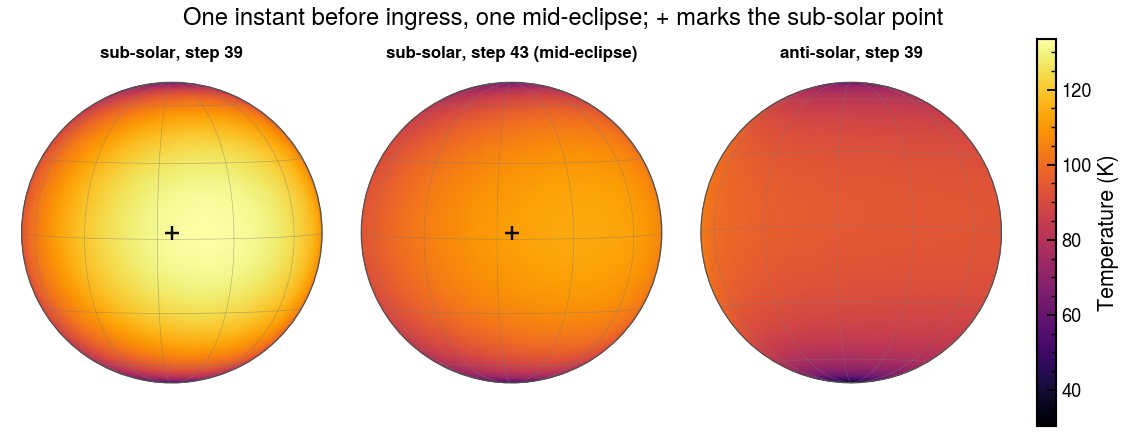

In [9]:
before, dark = int(eclipse[0] - 1), int(eclipse[len(eclipse) // 2])
sub = europa.subsolar_latlon(before)
T_before, T_dark = europa.field("temperature", before), europa.field("temperature", dark)

fig = europa.globe_grid(
    rows=[{"what": [T_before, T_dark, T_before], "label": "Temperature (K)", "mark": sub}],
    views=[(sub[0], sub[1], f"sub-solar, step {before}"),
           (sub[0], sub[1], f"sub-solar, step {dark} (mid-eclipse)"),
           (-sub[0], sub[1] + 180, f"anti-solar, step {before}")],
    suptitle="One instant before ingress, one mid-eclipse; + marks the sub-solar point")
lit = T_before > 100.0
print(f"the day side cooled by a median of {np.median(T_before[lit] - T_dark[lit]):.1f} K "
      f"between the two steps")

The whole sunlit hemisphere dims together — the signature of a shadow cast by
Jupiter rather than of a terminator moving across the surface. The third panel
is the same instant from the anti-solar direction, and it is barely darker than
the first: Europa's night side is only tens of kelvin below its day side, the
short-night effect quantified in section 5.

## 7. How long a spin-up is long enough?

A thermal model has to be told how long to run before anyone looks at the
answer, and `thermal.equilibration_orbits` is that setting. Too small does not
produce an obviously broken result; it produces a plausible one carrying
structure that came from the initial condition.

Two things could put longitudinal structure into the map from section 2.

*Physical.* An eclipse happens when Europa passes directly behind Jupiter as
seen from the Sun, so at that moment the sub-solar point coincides with the
sub-Jupiter point — and because Europa rotates synchronously, the sub-Jupiter
point is always the same place on the surface. Every eclipse therefore removes
sunlight from local noon at the *same* meridian, which should carry a permanent
cold notch a few degrees wide.

*Numerical.* If the spin-up is short, the deep layers still carry their starting
temperatures when the output window opens and relax during it. The sub-solar
longitude sweeps steadily through the window, so a slow drift in time becomes a
smooth ramp in longitude across the whole map.

The two respond differently to a longer spin-up: the notch stays, the ramp
shrinks. The cell below re-runs the identical config with
`--equilibration-orbits 5` and compares the equatorial ring, where every face
should reach the same peak.

In [10]:
short = engine.run_engine(pre.root / CONFIG, show=("Simulation completed in",),
                          extra_args=["--equilibration-orbits", "5",
                                      "--output", "output/quickstart_europa_diurnal_eq5"]
                          ).results()

lat, lon = europa.lat, europa.lon
ring = np.isclose(np.abs(lat), np.abs(lat).min(), atol=0.02)
order = np.argsort(lon[ring])
for label, field in (("5 orbits ", short.stat("temperature", "max")), ("20 orbits", tmax)):
    r = field[ring][order]
    print(f"equatorial ring, {label}: Tmax {r.min():.1f}-{r.max():.1f} K "
          f"(spread {r.max() - r.min():.2f} K), coldest at longitude "
          f"{lon[ring][order][np.argmin(r)]:+.0f} deg")

    Simulation completed in 4.887 seconds (4887 ms)
equatorial ring, 5 orbits : Tmax 127.1-135.7 K (spread 8.66 K), coldest at longitude +167 deg
equatorial ring, 20 orbits: Tmax 130.5-133.5 K (spread 3.06 K), coldest at longitude -5 deg


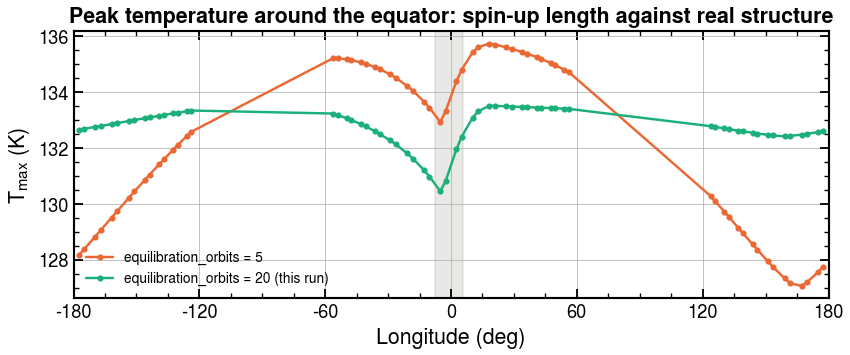

In [11]:
lon_in = europa.subsolar_latlon(int(eclipse[0]) - 1)[1]
lon_out = europa.subsolar_latlon(int(eclipse[-1]) + 1)[1]

fig, ax = plt.subplots(figsize=(8, 3.5))
for field, color, label in ((short.stat("temperature", "max"), "#eb6834",
                             "equilibration_orbits = 5"),
                            (tmax, "#1baf7a", "equilibration_orbits = 20 (this run)")):
    ax.plot(lon[ring][order], field[ring][order], "o-", ms=3, lw=1.6,
            color=color, label=label)
ax.axvspan(lon_out, lon_in, color="#8d8c82", alpha=0.2, zorder=0)
ax.set_xlabel("Longitude (deg)")
ax.set_ylabel(r"$T_\mathrm{max}$ (K)")
ax.set_xlim(-180, 180)
ax.set_xticks(range(-180, 181, 60))
ax.set_title("Peak temperature around the equator: spin-up length against real structure")
ax.legend(frameon=False, loc="lower left", fontsize=9)
ax.grid(True, linewidth=0.5)
fig.tight_layout()

The broad ramp is spin-up, not Europa: it collapses when the model is given more
orbits to forget its starting state. What survives is the narrow notch at the
shaded band — the sub-Jupiter meridian, exactly where the eclipse puts the Sun
overhead, a real feature of a synchronously rotating moon eclipsed once per
orbit in the same place every time.

This is why the config ships with 20 orbits rather than the 5 the surface layer
alone would need. Twenty is not exact either: `--equilibration-orbits 40` moves
peak temperature another 0.6 K RMS. Choose the spin-up by the accuracy the
question needs, and check it the way this section does — lengthen it and look at
what changes.

## 8. Driving the model with Europa's observed albedo map

Everything above used one Bond albedo, 0.5, for the whole moon. Europa is not
uniform: leading and trailing hemispheres differ, and bright ice plains sit next
to dark chaos and lineae. PTM3D can read a per-face Bond albedo map and use it
in the absorbed-flux boundary condition instead of the single default.

The maps ship in the project's data distribution rather than in git:

```bash
python3 scripts/fetch_data.py --dataset albedo-maps    # Moon + Europa, res3-res9
```

The engine picks the file whose resolution matches the mesh —
`mesh.resolution: 4` looks for `Europa_Albedo_res4.bin` — and falls back to the
uniform default, with a message in the log, if it does not find one.
`examples/quickstart_europa_albedo_map.yaml` differs from the config used above
in exactly one physics key, `illumination.use_albedo_map: true`, so the
difference between the two outputs is attributable to the map alone.

In [12]:
ALBEDO_MAP = "data/albedo_maps/Europa_Albedo_res4.bin"
paths.preflight([ALBEDO_MAP]).raise_if_missing()

mapped = engine.run_engine(pre.root / "examples/quickstart_europa_albedo_map.yaml",
                           show=("Albedo range", "Simulation completed in")).results()
albedo = europa.albedo_map(pre.root / ALBEDO_MAP)
tmax_map = mapped.stat("temperature", "max")
d_tmax = tmax_map - tmax
d_tmin = mapped.stat("temperature", "min") - tmin

    Albedo range: 0.140 to 0.897
    Albedo range: 0.140 to 0.897
    Simulation completed in 9.687 seconds (9687 ms)


In [13]:
print(f"map Bond albedo {albedo.min():.3f}-{albedo.max():.3f}, mean {albedo.mean():.3f} "
      f"against the uniform 0.500")
print(f"Tmax change: mean {d_tmax.mean():+.2f} K, RMS {d_tmax.std():.2f} K, "
      f"range {d_tmax.min():+.1f} to {d_tmax.max():+.1f} K")
print(f"Tmin change: mean {d_tmin.mean():+.2f} K, RMS {d_tmin.std():.2f} K")
print(f"correlation of the Tmax change with albedo: "
      f"r = {np.corrcoef(albedo, d_tmax)[0, 1]:+.2f}")

map Bond albedo 0.140-0.897, mean 0.549 against the uniform 0.500
Tmax change: mean -4.70 K, RMS 10.08 K, range -43.3 to +24.2 K
Tmin change: mean -2.21 K, RMS 4.48 K
correlation of the Tmax change with albedo: r = -0.99


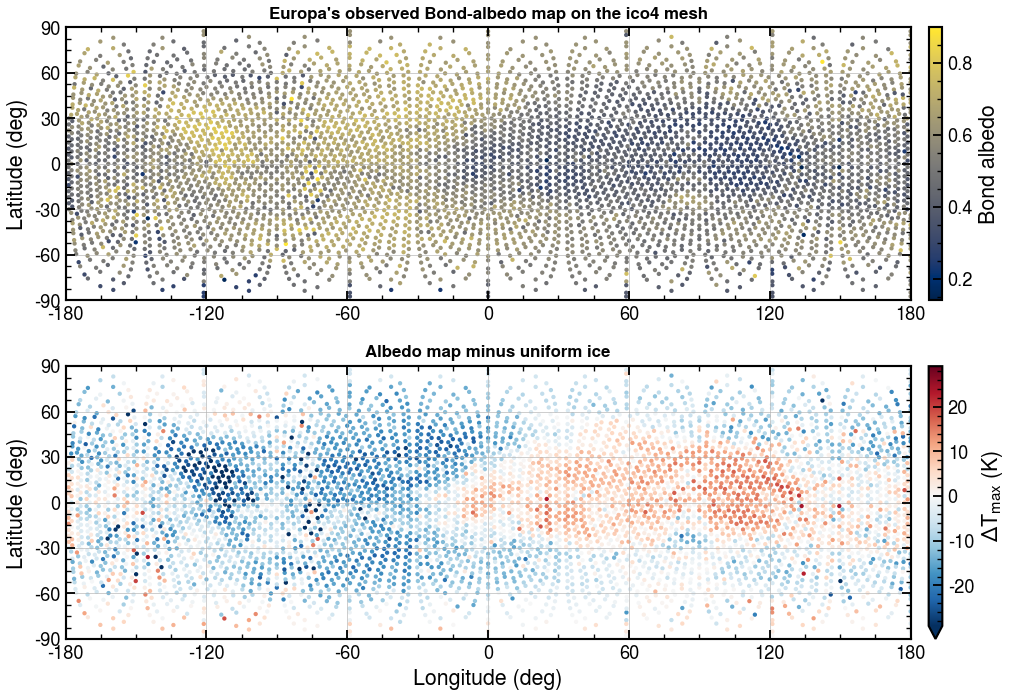

In [14]:
from matplotlib.colors import Normalize

fig, axes = plt.subplots(2, 1, figsize=(9.5, 6.6))
for ax, values, cmap, norm, label, title in (
        (axes[0], albedo, "cividis", Normalize(albedo.min(), albedo.max()),
         "Bond albedo", "Europa's observed Bond-albedo map on the ico4 mesh"),
        (axes[1], d_tmax, plots.CMAP_DIFF, plots.sym_norm(d_tmax),
         r"$\Delta T_\mathrm{max}$ (K)", "Albedo map minus uniform ice")):
    art = plots.scatter_map(ax, lat, lon, values, cmap=cmap, norm=norm,
                            title=title, xlabel=(ax is axes[-1]))
    plots.colorbar(fig, art, ax, label, values, norm, pad=0.02, fraction=0.046)
fig.tight_layout()

### Does the change follow the textbook law?

At radiative equilibrium the absorbed flux carries a factor $(1-A)$ and the
temperature is its fourth root, so replacing albedo $A_0$ by $A$ on the same
face should scale the peak temperature by

$$\frac{T}{T_0} = \left(\frac{1-A}{1-A_0}\right)^{1/4}.$$

That is a prediction with no free parameters. It is not expected to be exact:
`incidence_angle_albedo: true` means the absorbed flux uses a
directional-hemispheric albedo built from the Bond albedo rather than the Bond
albedo itself, and thermal inertia keeps the peak slightly below instantaneous
equilibrium.

law against run: mean residual -0.96 K, RMS 2.09 K, worst face 9.0 K


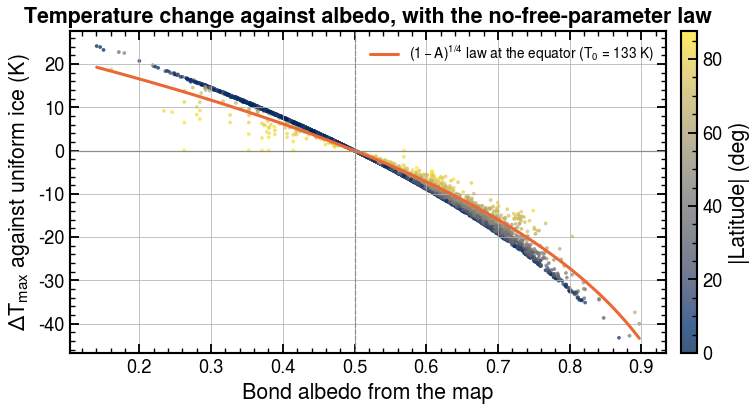

In [15]:
A0 = 0.5
residual = tmax_map - tmax * ((1.0 - albedo) / (1.0 - A0)) ** 0.25
equator = np.abs(lat) < 10.0
T0 = float(np.median(tmax[equator]))
a_curve = np.linspace(albedo.min(), albedo.max(), 200)

fig, ax = plt.subplots(figsize=(7.5, 4.0))
art = ax.scatter(albedo, d_tmax, c=np.abs(lat), cmap="cividis", s=6, alpha=0.75,
                 linewidths=0)
ax.plot(a_curve, T0 * (((1.0 - a_curve) / (1.0 - A0)) ** 0.25 - 1.0), lw=2,
        color="#eb6834", label=rf"$(1-A)^{{1/4}}$ law at the equator ($T_0$ = {T0:.0f} K)")
ax.axhline(0.0, color="#8d8c82", lw=0.8)
ax.axvline(A0, color="#8d8c82", lw=0.8, ls="--")
ax.set_xlabel("Bond albedo from the map")
ax.set_ylabel(r"$\Delta T_\mathrm{max}$ against uniform ice (K)")
ax.set_title("Temperature change against albedo, with the no-free-parameter law")
ax.legend(frameon=False, fontsize=9, loc="upper right")
ax.grid(True, linewidth=0.5)
plots.colorbar(fig, art, ax, "|Latitude| (deg)", pad=0.02)
fig.tight_layout()
print(f"law against run: mean residual {residual.mean():+.2f} K, "
      f"RMS {residual.std():.2f} K, worst face {np.abs(residual).max():.1f} K")

**Direction and size.** Darker faces absorb more and get hotter, brighter faces
get colder, and the split is at the 0.5 the uniform run assumed. The correlation
between albedo and temperature change is essentially $-1$, as it must be: at
this resolution, with radiation exchange off and no topography, albedo is the
only thing distinguishing one equatorial face from another.

**It is not a small correction.** The map spans Bond albedos from 0.14 to 0.90
against the single 0.5, moving peak temperatures by tens of kelvin — larger than
the eclipse signature. A Europa surface temperature quoted without saying which
albedo produced it is under-specified.

**The night side moves less.** The change in $T_\mathrm{min}$ is roughly half
the change in $T_\mathrm{max}$. Thermal inertia does that: the night-side
temperature is set by heat stored during the day and released slowly, which
damps the response to any change in absorbed flux.

**Where the law breaks, and why.** The equatorial curve tracks the dark points
closely and the residual is a couple of kelvin RMS. Points that sit above the
curve are high-latitude faces colored pale in the scatter: each face has its
own uniform-ice starting temperature, so off-equator faces follow shallower
versions of the same law.

**What this does not cover.** The map is a Bond albedo in the solar band only;
emissivity stays at 0.9 and the thermal properties stay uniform, so this is not
a compositional-units model. At ico4 a face spans about 250 km, which resolves
hemispheric contrast and nothing at the scale of individual chaos terrain;
`Europa_Albedo_res6.bin` and finer come with the same dataset.

## 9. Changing albedo, with a map already loaded

Albedo is the property to vary on Europa — section 8 has just shown it moving
peak temperature by tens of kelvin. The uniform knob is
`thermophysical.albedo_override`, or the `--albedo` flag, which delivers the
same value by the same route. `emissivity_override`, `ks_override` and
`kd_override` work the same way on any built-in body; tutorial 01, section 10
lists the full set and the two thermal-inertia conventions.

What matters here is what that knob does when a per-face map is *also*
configured, because `illumination.use_albedo_map` defaults to true in the
engine, so a config that says nothing about it is in the mapped state. The two
sweeps below are identical except for that one flag.

In [16]:
from ptm import Sweep

GRID = {"albedo": [0.3, 0.5, 0.7]}
uniform = Sweep(pre.root / CONFIG, grid=GRID,
                outdir=pre.root / "output/europa_albedo_uniform")
with_map = Sweep(pre.root / "examples/quickstart_europa_albedo_map.yaml", grid=GRID,
                 outdir=pre.root / "output/europa_albedo_mapped")
uniform.run()
with_map.run()

[sweep] engine /Users/paha3326/Projects/ptm-tut-thermophys/build-cpu/bin/ptm_thermal_sim (md5 04287bb7c7fb230d31588e8a11491ac8)
[sweep] axis albedo: 3 values -> --albedo (engine advertises it)


[sweep] ok   albedo-0p3 (10.4 s)


[sweep] ok   albedo-0p5 (10.2 s)


[sweep] ok   albedo-0p7 (10.1 s)
[sweep] 3 complete, 0 failed, 0 skipped, 30.8 s
[sweep] engine /Users/paha3326/Projects/ptm-tut-thermophys/build-cpu/bin/ptm_thermal_sim (md5 04287bb7c7fb230d31588e8a11491ac8)
[sweep] axis albedo: 3 values -> --albedo (engine advertises it)
[sweep]   note (albedo): illumination.use_albedo_map is in force, and a loaded per-face albedo map out-ranks the scalar albedo: the sweep axis would only move the equilibration seed and uncovered faces. Set illumination.use_albedo_map: false to sweep albedo directly.


[sweep] ok   albedo-0p3 (10.2 s)


[sweep] ok   albedo-0p5 (10.3 s)


[sweep] ok   albedo-0p7 (10.0 s)
[sweep] 3 complete, 0 failed, 0 skipped, 30.6 s


{'planned': 3,
 'skipped': 0,
 'complete': 3,
 'failed': 0,
 'not_attempted': 0,
 'wall_seconds': 30.6,
 'dry_run': False}

`Sweep` checked the base config before launching anything and said, for the
mapped arm only, that a loaded per-face map out-ranks the scalar. The engine
repeats the point in its own log. Both are worth reading rather than scrolling
past: this is a sweep that would otherwise run, finish, and produce a figure of
nothing.

use_albedo_map: false: equatorial median Tmax 113.41-147.31 K (span 33.90 K), 3 distinct checksums
use_albedo_map: true: equatorial median Tmax 133.18-133.32 K (span 0.14 K), 3 distinct checksums
the map's own albedo over that band: mean 0.500
WARNING WARNING: thermophysical.albedo_override = 0.300 is set AND a per-face albedo map is configured.


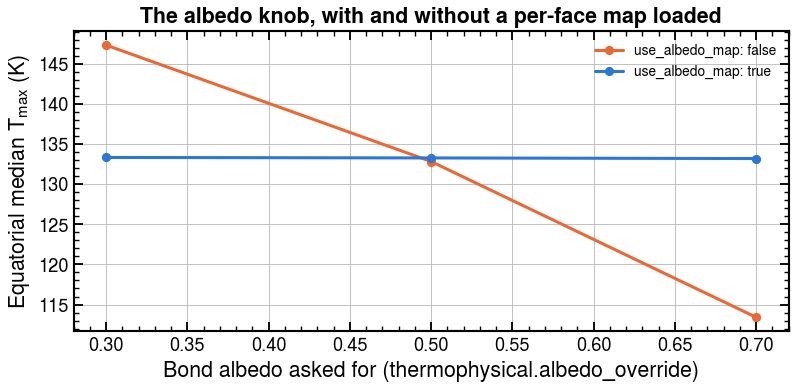

In [17]:
import hashlib

eq = np.abs(lat) < 10.0
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for sweep, color, label in ((uniform, "#eb6834", "use_albedo_map: false"),
                            (with_map, "#2a78d6", "use_albedo_map: true")):
    y = sweep.collect(lambda r: float(np.median(r.stat("temperature", "max")[eq])))
    seen = {hashlib.md5((pt.dir / "statistics" / "temperature_max.bin").read_bytes()
                        ).hexdigest() for pt in sweep.points}
    ax.plot(sweep.values("albedo"), y, "o-", lw=2, color=color, label=label)
    print(f"{label}: equatorial median Tmax {y.min():.2f}-{y.max():.2f} K "
          f"(span {y.max() - y.min():.2f} K), {len(seen)} distinct checksums")
print(f"the map's own albedo over that band: mean {albedo[eq].mean():.3f}")
print(next(l for l in (with_map.points[0].dir / "engine.log").read_text().splitlines()
           if "albedo map is configured" in l))
ax.set_xlabel("Bond albedo asked for (thermophysical.albedo_override)")
ax.set_ylabel(r"Equatorial median $T_\mathrm{max}$ (K)")
ax.set_title("The albedo knob, with and without a per-face map loaded")
ax.legend(frameon=False, fontsize=9)
ax.grid(True, linewidth=0.5)
fig.tight_layout()

**The map wins.** Moving the albedo asked for from 0.3 to 0.7 changes the
equatorial median peak temperature by 33.9 K with no map loaded, and by 0.14 K
with one. The map is what the absorbed-flux boundary condition reads; the
scalar is left setting the equilibration seed and the fallback for faces the
map does not cover.

**This is where the checksum habit runs out.** All three mapped points have
distinct checksums, so the axis is not dead in the strict sense — and a
distinctness test would have passed it. Distinctness is all a checksum can
prove. The magnitude is what says whether the knob did what was meant, and
0.14 K against 33.9 K says it did not. Use the checksum to catch an axis that
changed nothing, and a number with units to decide whether what it changed
matters.

**The crossing near 0.5 is a coincidence of this band.** The two lines meet
where the uniform value happens to match the map's own mean over the equatorial
faces being averaged, printed above. It is not the override taking effect.

**To sweep albedo, own the map.** Set `illumination.use_albedo_map: false` and
the scalar governs, which is the orange line and what tutorial 01's section 10
does on the Moon. Keep the map and the way to change albedo is to change the
map: `illumination.albedo_map` names a file, and the binary section 8 read is a
`size_t` count followed by one `float64` per face, so a rescaled copy is a few
lines of NumPy around `ptm.readers.read_albedo_map`.

**What this does not cover.** Both arms hold emissivity, thermal inertia and
internal heat flux at Europa's built-in values, so nothing here says how those
respond; a per-face albedo map does not make this a compositional model. And
the same precedence question exists for the H-parameter and thermal-inertia
maps, which were not loaded in either arm.

## 10. Exercises

1. **A window with no eclipse.** The eclipse is real SPICE geometry, not a
   config flag, and every full-orbit window contains exactly one. For a
   comparison window try `start_time: '2025-01-02T00:00:00'` with
   `duration_days: 1.5` and `timesteps: 81`, which sits entirely between this
   eclipse and the next, and compare the uninterrupted peak with this run's
   post-eclipse peak.

2. **`include_primary_reflection: false`.** Re-run with it false. In the final
   Results block, `Primary reflected` drops to about zero while `Primary IR` is
   essentially unchanged — the asymmetric gating described in section 3.

3. **Resolution.** Raise `mesh.resolution` to `5` (20,480 faces;
   `Europa_Albedo_res5.bin` ships with the same dataset) and re-run the section
   8 pair. The hemispheric contrast should barely move while the spread of
   per-face changes grows, because a finer mesh resolves patches that ico4
   averages together. `scripts/ptm_mem_estimate.py --faces 20480 --steps 192`
   sizes it first.

4. **Sweep albedo across the observed range.** Section 9's uniform arm spanned
   0.3-0.7; Europa's map spans 0.14 to 0.90. Re-run that arm at the endpoints
   and compare the resulting spread in peak temperature with the per-face spread
   the map itself produces, -43.3 to +24.2 K from section 8.

